# Airline Review Analysis - Notebook 2: Exploratory Data Analysis (EDA)

In this notebook I explore the cleaned reviews using charts and simple summary tables. The aim is to understand the data (ratings, recommendations, airlines, years and review length) before building any NLP models.

Input: `data/reviews_clean.csv` (created in Notebook 1)

## 1. Loading the cleaned data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv("data/reviews_clean.csv", parse_dates=["review_date"])
print(df.shape)
df.head(3)

(64331, 23)


,airline,airline_name,review_date,year,date_flown,over_all_rating,recommended,recommended_bin,review_header,review_text,...,seat_type,aircraft,route,seat_comfort,cabin_staff_service,food__beverages,inflight_entertainment,ground_service,wifi__connectivity,value_for_money
0,Spicejet,spicejet,2025-08-04,2025,2025-08-01,1.0,no,0,showed zero empathy for passengers,My afternoon flight was delayed and eventually...,...,Economy Class,NaN,dubai_to_kochi,1.0,2.0,2.0,2.0,1.0,1.0,1.0
1,Spicejet,spicejet,2025-07-21,2025,2025-07-01,2.0,no,0,Extremely dissatisfied,The flight was postponed 3 times with insuffic...,...,Economy Class,NaN,pune_to_dubai,1.0,3.0,NaN,NaN,3.0,NaN,2.0
2,Spicejet,spicejet,2025-04-19,2025,2025-04-01,2.0,no,0,Very bad experience,They will charge you for your hand baggage if ...,...,Economy Class,NaN,mumbai_to_kolkata,3.0,3.0,3.0,NaN,1.0,NaN,2.0


## 2. Basic summary

In [2]:
print("number of reviews:", len(df))
print("number of airlines:", df["airline"].nunique())
print("from", df["review_date"].min().date(), "to", df["review_date"].max().date())
print("average overall rating:", round(df["over_all_rating"].mean(), 2))
print("percent recommended:", round(df["recommended_bin"].mean() * 100, 1))
print("median words per review:", int(df["n_words"].median()))

number of reviews: 64331
number of airlines: 109
from 2015-01-05 to 2025-08-07
average overall rating: 4.35
percent recommended: 38.3
median words per review: 104


## 3. Overall rating

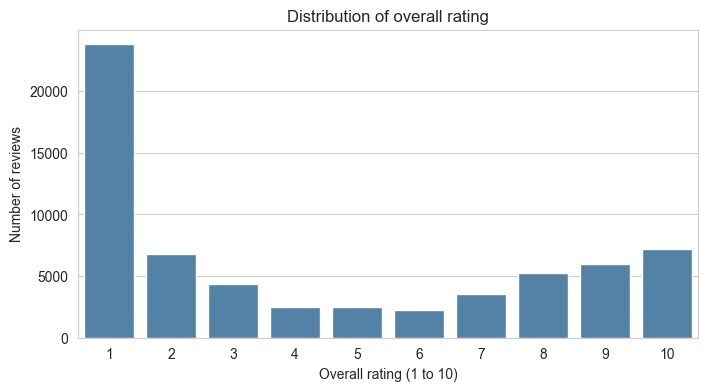

In [3]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x=df["over_all_rating"].dropna().astype(int), color="steelblue")
plt.title("Distribution of overall rating")
plt.xlabel("Overall rating (1 to 10)")
plt.ylabel("Number of reviews")
plt.show()

Most reviews are either very low (rating 1) or very high (9 or 10), with few in the middle. People mostly write a review when they are very unhappy or very happy.

## 4. Recommended or not

recommended
no     39715
yes    24616
Name: count, dtype: int64
recommended
no     61.7
yes    38.3
Name: count, dtype: float64


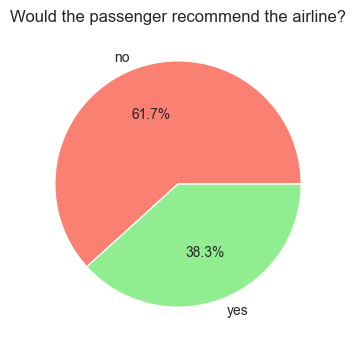

In [4]:
rec_counts = df["recommended"].value_counts()
print(rec_counts)
print((rec_counts / len(df) * 100).round(1))

plt.figure(figsize=(4, 4))
plt.pie(rec_counts, labels=rec_counts.index, autopct="%1.1f%%", colors=["salmon", "lightgreen"])
plt.title("Would the passenger recommend the airline?")
plt.show()

About 38% of passengers recommend the airline and 62% do not, so the two classes are not equal but not extremely unbalanced either.

## 5. Change over the years

Number of reviews per year, and the percentage of passengers who recommend the airline each year. Note that 2025 only goes up to August.

In [5]:
by_year = df.groupby("year").agg(reviews=("recommended_bin", "count"),
                                 recommend_rate=("recommended_bin", "mean"))
by_year["recommend_rate"] = (by_year["recommend_rate"] * 100).round(1)
by_year

,reviews,recommend_rate
year,,
2015,7802,56.3
2016,7453,58.2
2017,7252,50.0
2018,7958,39.2
2019,8765,33.0
2020,3387,28.9
2021,3493,20.4
2022,6571,20.7
2023,6155,25.4


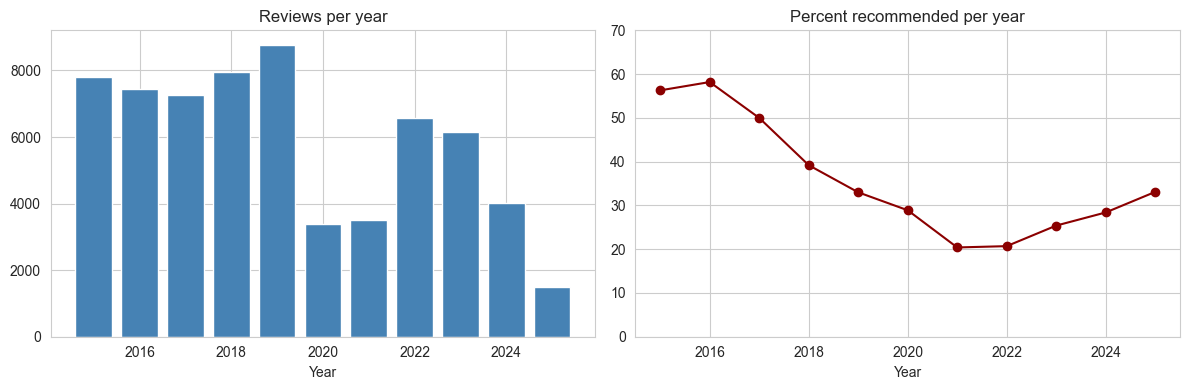

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(by_year.index, by_year["reviews"], color="steelblue")
axes[0].set_title("Reviews per year")
axes[0].set_xlabel("Year")

axes[1].plot(by_year.index, by_year["recommend_rate"], marker="o", color="darkred")
axes[1].set_title("Percent recommended per year")
axes[1].set_xlabel("Year")
axes[1].set_ylim(0, 70)

plt.tight_layout()
plt.show()

The percentage of passengers recommending an airline dropped from about 56% in 2015 to about 20% in 2021, and has recovered a little since. The number of reviews also fell during 2020 and 2021 (COVID-19 period).

## 6. Airlines

First the airlines with the most reviews.

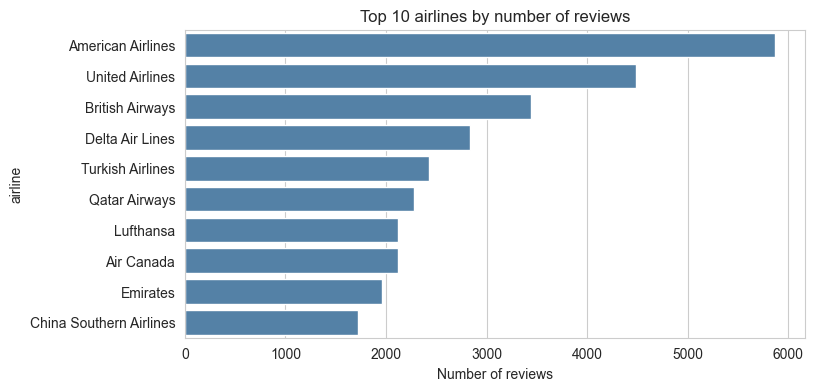

In [7]:
top10 = df["airline"].value_counts().head(10)

plt.figure(figsize=(8, 4))
sns.barplot(x=top10.values, y=top10.index, color="steelblue")
plt.title("Top 10 airlines by number of reviews")
plt.xlabel("Number of reviews")
plt.show()

Next, which airlines have the highest and lowest recommendation rate. An airline with only a few reviews can look very good or very bad by chance, so I only include airlines with at least 300 reviews.

In [8]:
airline_stats = df.groupby("airline").agg(reviews=("recommended_bin", "count"),
                                          recommend_rate=("recommended_bin", "mean"))
airline_stats["recommend_rate"] = (airline_stats["recommend_rate"] * 100).round(1)
big_airlines = airline_stats[airline_stats["reviews"] >= 300].sort_values("recommend_rate")

print("airlines with at least 300 reviews:", len(big_airlines))
print()
print("Lowest 5:")
print(big_airlines.head(5))
print()
print("Highest 5:")
print(big_airlines.tail(5))

airlines with at least 300 reviews: 52

Lowest 5:
                   reviews  recommend_rate
airline                                   
American Airlines     5872            12.5
Jetblue Airways       1456            17.9
United Airlines       4486            18.1
Porter Airlines        309            21.4
Jetstar Airways       1021            22.0

Highest 5:
                         reviews  recommend_rate
airline                                         
Eva Air                      388            79.9
Ana All Nippon Airways       377            82.0
Garuda Indonesia             679            84.4
Hainan Airlines              339            87.3
China Southern Airlines     1725            88.8


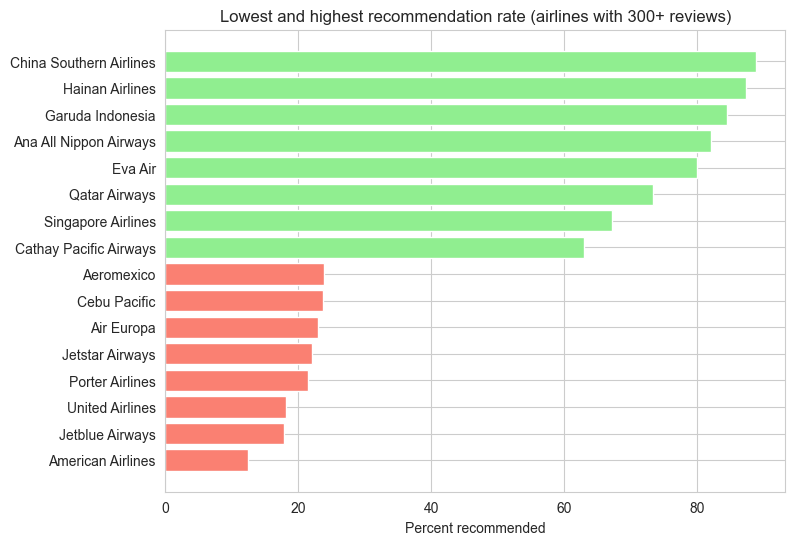

In [9]:
extremes = pd.concat([big_airlines.head(8), big_airlines.tail(8)])

plt.figure(figsize=(8, 6))
colors = ["salmon"] * 8 + ["lightgreen"] * 8
plt.barh(extremes.index, extremes["recommend_rate"], color=colors)
plt.title("Lowest and highest recommendation rate (airlines with 300+ reviews)")
plt.xlabel("Percent recommended")
plt.show()

The difference between airlines is very large: the lowest rate is around 12% and the highest is close to 90%.

## 7. Ratings for each part of the flight

The dataset has separate 1 to 5 ratings for seat, staff, food and so on. Many of these are empty, so I look at both the average and the percentage missing.

In [10]:
rating_cols = ["seat_comfort", "cabin_staff_service", "food__beverages",
               "inflight_entertainment", "ground_service", "wifi__connectivity", "value_for_money"]

rating_summary = pd.DataFrame({
    "average": df[rating_cols].mean().round(2),
    "percent_missing": (df[rating_cols].isna().mean() * 100).round(1)
})
rating_summary

,average,percent_missing
seat_comfort,2.84,5.4
cabin_staff_service,3.07,5.7
food__beverages,2.80,19.4
inflight_entertainment,2.83,32.7
ground_service,2.58,7.2
wifi__connectivity,2.21,63.5
value_for_money,2.61,0.0


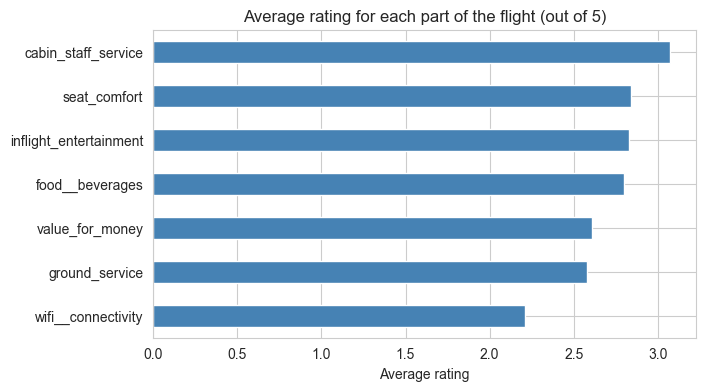

In [11]:
rating_summary["average"].sort_values().plot(kind="barh", figsize=(7, 4), color="steelblue")
plt.title("Average rating for each part of the flight (out of 5)")
plt.xlabel("Average rating")
plt.show()

All averages are below 3 out of 5. WiFi has the lowest average (about 2.2), but it is also missing for most reviews, so this is based on fewer passengers.

### How are the ratings related to each other?

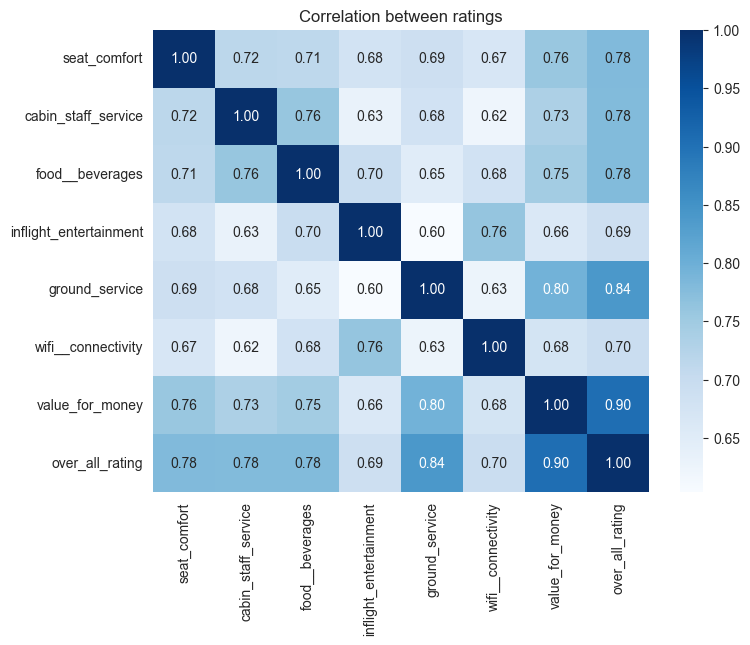

In [12]:
corr_cols = rating_cols + ["over_all_rating"]
corr = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues")
plt.title("Correlation between ratings")
plt.show()

All ratings are strongly related to each other. `value_for_money` is almost the same as the overall rating (correlation 0.90), so if I try to predict the overall opinion from the other ratings it would be too easy. This is why later I will work from the review text instead.

## 8. Length of the reviews

count    64331.0
mean       135.2
std        105.5
min         10.0
25%         63.0
50%        104.0
75%        173.0
max        994.0
Name: n_words, dtype: float64

average words in reviews that recommend: 111.7
average words in reviews that do not recommend: 149.7


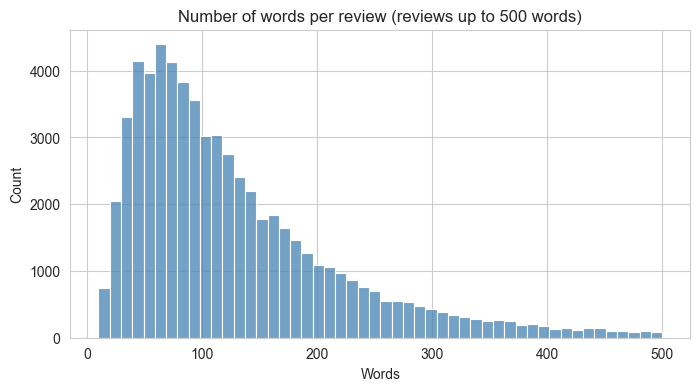

In [13]:
print(df["n_words"].describe().round(1))
print()
print("average words in reviews that recommend:", round(df[df["recommended"] == "yes"]["n_words"].mean(), 1))
print("average words in reviews that do not recommend:", round(df[df["recommended"] == "no"]["n_words"].mean(), 1))

plt.figure(figsize=(8, 4))
sns.histplot(df[df["n_words"] <= 500]["n_words"], bins=50, color="steelblue")
plt.title("Number of words per review (reviews up to 500 words)")
plt.xlabel("Words")
plt.show()

Most reviews are short, but a few are very long. Reviews that do not recommend the airline tend to be longer, which makes sense because people explain what went wrong.

## 9. Type of traveller and seat class

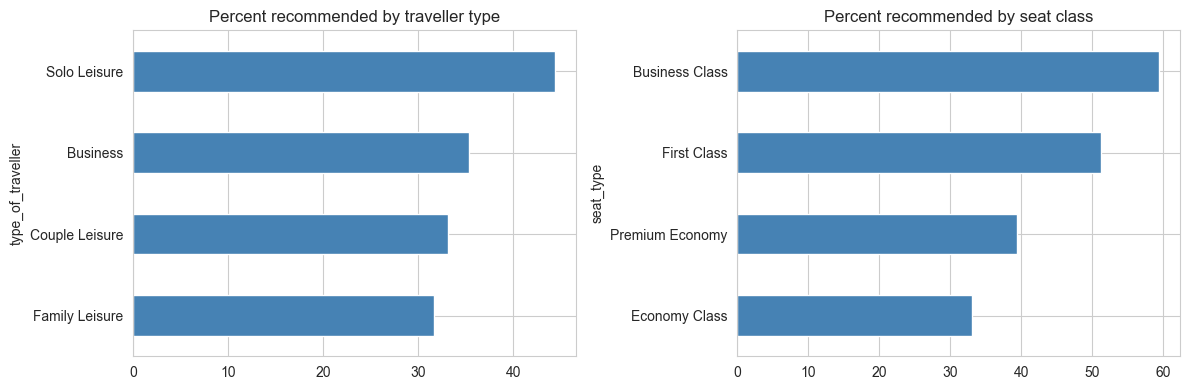

type_of_traveller
Family Leisure    31.6
Couple Leisure    33.2
Business          35.4
Solo Leisure      44.3
Name: recommended_bin, dtype: float64

seat_type
Economy Class      33.0
Premium Economy    39.4
First Class        51.2
Business Class     59.4
Name: recommended_bin, dtype: float64


In [14]:
traveller = df.groupby("type_of_traveller")["recommended_bin"].mean().sort_values() * 100
seat = df.groupby("seat_type")["recommended_bin"].mean().sort_values() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
traveller.plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Percent recommended by traveller type")
seat.plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Percent recommended by seat class")
plt.tight_layout()
plt.show()

print(traveller.round(1))
print()
print(seat.round(1))

Business and first class passengers are more likely to recommend the airline (about 59% and 51%) than economy passengers (about 33%). Solo leisure travellers are the happiest group of travellers.

### Verified and unverified reviews

The `verified` tag only exists for newer reviews, so I compare the two groups using reviews from 2018 onwards.

In [15]:
recent = df[(df["year"] >= 2018) & (df["verified"] != "unknown")]
print(recent.groupby("verified")["recommended_bin"].agg(["count", "mean"]).round(3))

            count   mean
verified                
unverified   9925  0.202
verified    31815  0.321


Verified reviews are recommended more often (about 32%) than unverified ones (about 20%).

## Summary of what I found

- The ratings are mostly very low or very high, and only about 38% of passengers recommend their airline.
- Recommendation fell strongly from 2015 to 2021 and has recovered slightly.
- Airlines differ a lot in how often they are recommended.
- Each part of the flight is rated below 3 out of 5 on average, and WiFi is the lowest.
- The separate ratings are strongly related to the overall rating, so I will use the review text itself for the NLP models.
- Reviews that do not recommend the airline are longer, and business and first class passengers are happier than economy passengers.

Next notebook: text preprocessing (tokenization, stopwords, stemming, lemmatization and n-grams).